# 05a — Donut foundations: from a whole card to generated tokens

**Phase 4, Workshop 0 · Executed research notebook · Training identities only**

In Phase 3, we told TrOCR where each field was by giving it seven crops. Here
we give Donut the whole card. Eventually it must learn both **what the text says**
and **which field the text belongs to**. Today we investigate the machinery before
building that training task.

By the end, you should be able to explain and inspect:

1. The difference between the canonical card, processed tensor, encoder features,
   token IDs, generated sequence, and parsed fields.
2. Why preprocessing can rotate a card or make small text unreadable.
3. How a Swin encoder and an autoregressive text decoder cooperate.
4. Why writing a new field tag does not teach a pretrained model a new task.
5. What loading/inference memory tells us—and what it cannot tell us about training.

**The experiment:** one training identity, its template and rectified photo,
one exact pretrained checkpoint, and a short greedy generation. No optimization,
validation selection, test scoring, or accuracy claim occurs here.

Navigation: [workshop plan](../docs/workshops/phase-4.md) ·
[concept guide](../docs/learning/ocr-free.md) ·
[experiment report](../docs/experiments/donut-feasibility.md) ·
[experimental contract](../EXPERIMENT_DESIGN.md).

## How to work through this notebook

Read the explanation, make a prediction, run the next cell, then compare your
prediction with the displayed result. The cells are deliberately sequential;
use **Restart Kernel and Run All** to verify that nothing depends on hidden state.
Keep a separate copy for exercises so the executed research record stays intact.

**Setup:** open the repository in your notebook editor and choose its `.venv`
Python interpreter. The environment needs the package and research dependencies
from `pyproject.toml`; the [OCR usage guide](../docs/guides/ocr-usage.md) documents
the existing environment. This notebook uses Transformers 5 APIs and explicitly
chooses the PIL processor backend rather than assuming an old tutorial still fits.

From the repository root, prepare the pinned public weights once:

```bash
.venv/bin/python experiments/prepare_donut_foundations.py
```

The download is approximately 815 MB and stays under ignored `checkpoints/`.
Afterward this notebook is offline. To execute and save a new evidence run:

```bash
.venv/bin/python experiments/run_donut_foundations.py --device cuda:0
```

Use `--device cpu` if CUDA is unavailable; expect different timings. For an
interactive CPU session, set `DONUT_DEVICE=cpu` before starting Jupyter. If a
CUDA session fails, check `nvidia-smi`, the selected interpreter, and sandbox GPU
permissions. Do not silently substitute CPU and describe the result as GPU work.

A `TqdmWarning` about missing `IProgress` may appear in this environment. It
means the optional widget progress display is unavailable; plain progress and
model execution still work. It does not require changing model libraries.

**Reading outputs:** an `assert` checks an experimental invariant. A table or
plot helps interpretation. A reflection question is learning work for you;
successful execution does not mean the reflection has been answered.

## 1. Set up a reproducible session

First locate the repository, read the versioned investigation settings, and
choose the requested device explicitly. Fix the seed and CPU thread counts to
make the session easier to reproduce. These controls apply to this experiment,
not to importing the reusable package.

**Predict first:** should `torch.cuda.is_available()` tell us that a complete
training step fits in GPU memory? It only tells us whether PyTorch can use CUDA.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import gc
import hashlib
import importlib.metadata
import inspect
import json
import os
import platform
import time

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import torch
from IPython.display import Markdown, display
from transformers import (
    AutoTokenizer, DonutImageProcessorPil, DonutProcessor,
    GenerationConfig, VisionEncoderDecoderModel,
)
from kyc_router.normalization import normalize_document_values
from kyc_router.schema import RAW_TO_CANONICAL, REQUIRED_FIELDS

here = Path.cwd().resolve()
ROOT = next((p for p in [here, *here.parents] if (p / 'PROJECT.md').is_file()), None)
assert ROOT is not None, 'Open this notebook inside the repository.'
policy_path = ROOT / 'configs/donut_foundations_v1.json'
policy = json.loads(policy_path.read_text())
run_id = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN = Path(os.environ.get('DONUT_RUN_DIR', ROOT / 'outputs/phase4_foundations' / run_id))
RUN.mkdir(parents=True, exist_ok=True)
os.environ['HF_HUB_OFFLINE'] = '1'
os.environ['TRANSFORMERS_OFFLINE'] = '1'
torch.manual_seed(policy['seed'])
np.random.seed(policy['seed'])
torch.set_num_threads(policy['torch_threads'])
cv2.setNumThreads(policy['opencv_threads'])
device = torch.device(os.environ.get('DONUT_DEVICE', 'cuda:0'))
if device.type == 'cuda':
    assert torch.cuda.is_available(), 'CUDA unavailable: fix GPU access or explicitly choose CPU.'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
print('Repository:', ROOT)
print('Evidence directory:', RUN.relative_to(ROOT))
print('Requested device:', device)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /home/raspiestchip/kyc-router
Evidence directory: outputs/phase4_foundations/20261013T130934816247Z
Requested device: cuda:0


### 1.1 Memory has several meanings

**Process RSS** is physical CPU memory attributed to this Python process.
**CUDA allocated** is live tensor memory tracked by PyTorch. **CUDA reserved**
also includes blocks kept by its allocator for reuse. **Device free** includes
effects from the desktop and other processes, so it is not the same denominator.
Peak counters measure the maximum since we last reset them, not lifetime GPU use.

We record these separately. Synchronization makes outstanding GPU work complete
before reading a timing boundary; CPU wall time alone can otherwise end too early.

In [2]:
def sha256(path):
    with Path(path).open('rb') as handle:
        return hashlib.file_digest(handle, 'sha256').hexdigest()

def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + '\n')

def synchronize():
    if device.type == 'cuda':
        torch.cuda.synchronize(device)

def memory_snapshot(label):
    synchronize()
    row = {'stage': label, 'process_rss_mib': psutil.Process().memory_info().rss / 2**20}
    if device.type == 'cuda':
        free, total = torch.cuda.mem_get_info(device)
        row.update(
            cuda_allocated_mib=torch.cuda.memory_allocated(device) / 2**20,
            cuda_reserved_mib=torch.cuda.memory_reserved(device) / 2**20,
            cuda_peak_allocated_mib=torch.cuda.max_memory_allocated(device) / 2**20,
            cuda_peak_reserved_mib=torch.cuda.max_memory_reserved(device) / 2**20,
            device_free_mib=free / 2**20, device_total_mib=total / 2**20,
        )
    return row

packages = ['torch', 'torchvision', 'transformers', 'huggingface_hub',
            'pillow', 'numpy', 'pandas', 'opencv-python', 'nbformat', 'nbclient', 'psutil']
environment = {
    'python': platform.python_version(), 'platform': platform.platform(),
    'cpu': platform.processor(), 'logical_cpus': os.cpu_count(),
    'ram_gib': psutil.virtual_memory().total / 2**30,
    'packages': {p: importlib.metadata.version(p) for p in packages},
    'device': str(device), 'cuda_build': torch.version.cuda,
    'torch_threads': torch.get_num_threads(), 'opencv_threads': cv2.getNumThreads(),
}
if device.type == 'cuda':
    environment.update(gpu=torch.cuda.get_device_name(device),
                       compute_capability=list(torch.cuda.get_device_capability(device)))
memory_rows = [memory_snapshot('session before loading')]
write_json(RUN / 'environment.json', environment)
display(pd.Series(environment, name='recorded environment').to_frame())

,recorded environment
python,3.14.7
platform,Linux-7.2.5-200.fc44.x86_64-x86_64-with-glibc2.43
cpu,
logical_cpus,12
ram_gib,31.077206
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda:0
cuda_build,13.0
torch_threads,4
opencv_threads,1


## 2. Load one permitted identity and reconstruct canonical inputs

Read the split manifest **before opening an image**. We select the first training
identity in sorted order; selection does not depend on model performance.
Reading split assignments is permitted; loading test images or their field values
is outside this workshop.

We open only this identity's template and photo. The shared VIA files contain
other records, so the adapter selects only the chosen filename and never displays
other transcriptions. Templates are resized; photos use the established annotated
quadrilateral and Phase 2 homography. This repeats those few transparent geometry
operations rather than executing an earlier notebook inside this one.

**Predict first:** the two canonical arrays will have the same shape. Will their
pixels be equal? Rectification aligns geometry; it cannot remove capture artifacts.

In [3]:
split_path = ROOT / 'splits/alb_id_v1.csv'
split = pd.read_csv(split_path, dtype={'sample_id': 'string'})
assert split['identity_key'].is_unique
assert split['split'].value_counts().to_dict() == {'train': 70, 'validation': 15, 'test': 15}
chosen = split.loc[split['split'].eq('train')].sort_values('identity_key').iloc[0]
assert chosen['split'] == 'train' and chosen['document_type'] == 'alb_id'
identity_key = chosen['identity_key']
filename = f"{chosen['sample_id']}.jpg"
dataset = ROOT / 'data/raw'
geometry_path = ROOT / 'configs/controlled_degradations_v1.json'
geometry_policy = json.loads(geometry_path.read_text())
width, height = json.loads((ROOT / 'configs/ocr_pipeline_v1.json').read_text())['canonical_size']

def selected_record(source):
    annotation_path = dataset / source / 'annotations/alb_id.json'
    metadata = json.loads(annotation_path.read_text())['_via_img_metadata']
    matches = [r for r in metadata.values() if r['filename'] == filename]
    assert len(matches) == 1, f'Expected exactly one annotation for {filename}.'
    return matches[0], annotation_path

def region(record, name):
    matches = [r for r in record['regions'] if r['region_attributes'].get('field_name') == name]
    assert len(matches) == 1, f'Expected one region: {name}'
    return matches[0]

template_record, template_annotations = selected_record('templates')
photo_record, photo_annotations = selected_record('photo')
image_paths = {s: dataset / folder / 'images/alb_id' / filename
               for s, folder in [('template', 'templates'), ('photo', 'photo')]}
bgr = {s: cv2.imread(str(path)) for s, path in image_paths.items()}
assert all(image is not None for image in bgr.values()), 'Restore MIDV data; see setup guide.'
print('Selected:', identity_key, '| split:', chosen['split'])
print('Source shapes:', {s: image.shape for s, image in bgr.items()})

Selected: alb_id/02 | split: train
Source shapes: {'template': (1360, 2167, 3), 'photo': (4032, 2268, 3)}


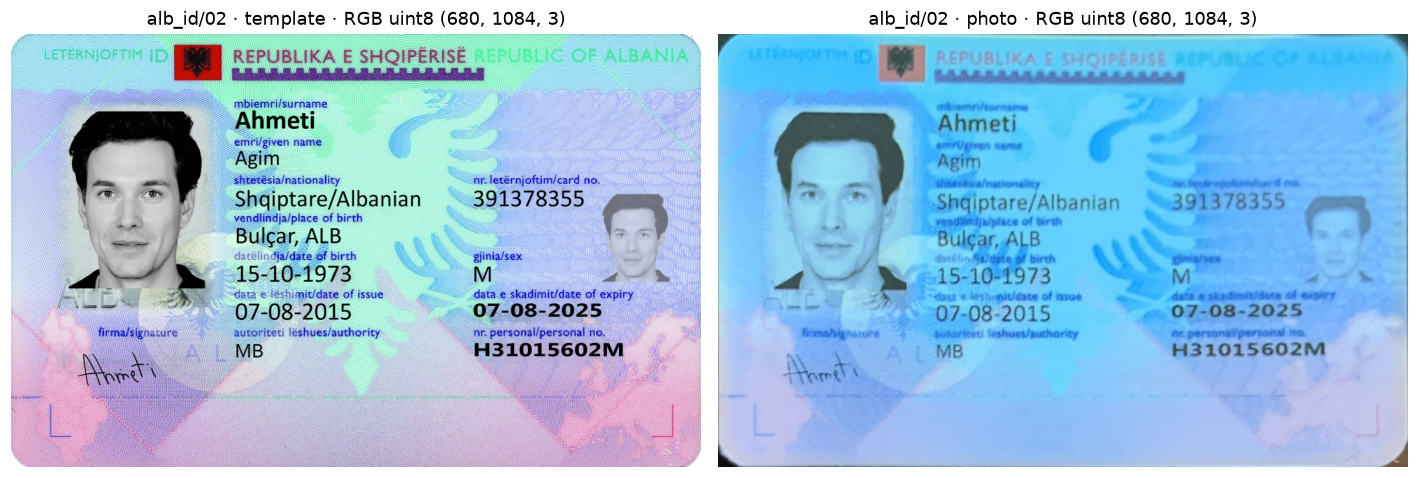

In [4]:
quad_shape = region(photo_record, 'doc_quad')['shape_attributes']
corners = np.asarray(list(zip(quad_shape['all_points_x'], quad_shape['all_points_y'])), dtype=np.float32)
assert corners.shape == (4, 2)
destination = np.asarray([[0, 0], [width - 1, 0], [width - 1, height - 1], [0, height - 1]], dtype=np.float32)
homography = cv2.getPerspectiveTransform(corners, destination)
canonical = {
    'template': cv2.cvtColor(cv2.resize(bgr['template'], (width, height), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB),
    'photo': cv2.cvtColor(cv2.warpPerspective(bgr['photo'], homography, (width, height)), cv2.COLOR_BGR2RGB),
}
for source, image in canonical.items():
    assert image.shape == (680, 1084, 3) and image.dtype == np.uint8
    assert image.flags.c_contiguous
    from PIL import Image
    Image.fromarray(image).save(RUN / f'canonical_{source}.png')
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for axis, (source, image) in zip(axes, canonical.items()):
    axis.imshow(image)
    axis.set_title(f'{identity_key} · {source} · RGB uint8 {image.shape}')
    axis.axis('off')
fig.tight_layout()
fig.savefig(RUN / 'canonical_pair.png', bbox_inches='tight')
plt.show()

### 2.1 Ground truth belongs beside the experiment, not inside inference

Display the seven annotated values so you know what a future extractor should
return. Keep the original and normalized forms separate. The values below never
enter the image encoder or the decoder prompt. Knowing the identity key helps us
audit the sample, but it is also excluded from model inputs.

**Pause:** explain why passing the surname in a prompt would invalidate this
extraction experiment, even if the resulting answer looked perfect.

In [5]:
truth_raw = {canonical_name: region(template_record, raw_name)['region_attributes']['value']
             for raw_name, canonical_name in RAW_TO_CANONICAL.items()}
truth_normalized = normalize_document_values(truth_raw)
assert tuple(truth_raw) == REQUIRED_FIELDS
display(pd.DataFrame({'annotation': truth_raw, 'normalized reference': truth_normalized}))

,annotation,normalized reference
document_number,391378355,391378355
surname,Ahmeti,ahmeti
given_names,Agim,agim
date_of_birth,15-10-1973,1973-10-15
expiry_date,07-08-2025,2025-08-07
nationality,Shqiptare/Albanian,shqiptare/albanian
sex,M,M


## 3. Verify the exact artifacts and inspect the installed API

A model name is a moving repository reference; a commit revision identifies the
snapshot we acquired. Verify every downloaded file against its acquisition
manifest before using it. We also save those hashes with this run.

The checkpoint predates our installed Transformers version. Rather than copying
an old high-level `image-to-text` tutorial, we inspect and call the concrete
processor and `VisionEncoderDecoderModel` APIs. We explicitly choose the PIL
backend so resize behavior is identifiable and repeatable.

**If this cell fails:** rerun the preparation command from the setup section.
Do not switch to `main`, another task checkpoint, or an unrecorded local model.

In [6]:
checkpoint = ROOT / policy['checkpoint_relative_path']
manifest_path = checkpoint / 'artifact_manifest.json'
assert manifest_path.is_file(), 'Run experiments/prepare_donut_foundations.py first.'
artifacts = json.loads(manifest_path.read_text())
assert artifacts['model_id'] == policy['model_id'] and artifacts['revision'] == policy['revision']
assert set(artifacts['files_sha256']) == set(policy['download_files'])
artifact_rows = []
for name, expected in artifacts['files_sha256'].items():
    path = checkpoint / name
    actual = sha256(path)
    assert actual == expected, f'Checkpoint checksum mismatch: {name}'
    artifact_rows.append({'file': name, 'size_mib': path.stat().st_size / 2**20, 'sha256': actual})
write_json(RUN / 'checkpoint_manifest.json', artifacts)
saved_config = json.loads((checkpoint / 'config.json').read_text())
saved_preprocessor = json.loads((checkpoint / 'preprocessor_config.json').read_text())
print('Pinned model:', policy['model_id'])
print('Pinned revision:', policy['revision'])
display(pd.DataFrame(artifact_rows))
print('Processor API:', inspect.signature(DonutImageProcessorPil.preprocess))
print('Model forward API:', inspect.signature(VisionEncoderDecoderModel.forward))

Pinned model: naver-clova-ix/donut-base
Pinned revision: a959cf33c20e09215873e338299c900f57047c61


,file,size_mib,sha256
0,config.json,0.004522,99df7199ba7abaa21719c474045d9bc9b1d0913a29f75a...
1,preprocessor_config.json,0.000345,16c05b40e0427fa76397c3f4ef4a6c0653119874ce106d...
2,pytorch_model.bin,771.683406,749f6e487d0cdbd7362d8b6a909174b93506d8631da0d1...
3,added_tokens.json,0.000068,01de563cc20356afb31f67f73ec3e603d7dc8fa34f1211...
4,sentencepiece.bpe.model,1.236196,cb9e3dce4c326195d08fc3dd0f7e2eee1da8595c847bf4...
5,special_tokens_map.json,0.000339,3f8273f4fb0dbec71247f4a7499a05be4bb898e452e6dc...
6,tokenizer.json,3.825217,6f462e51a599283723d97c3e6e4327461c27be74eb1b07...
7,tokenizer_config.json,0.000494,9a7d4c24159d533b4625358c84a425d6a5ec9e498af5c2...


Processor API: (self, images: ForwardRef('PIL.Image.Image') | numpy.ndarray | ForwardRef('torch.Tensor') | list['PIL.Image.Image'] | list[numpy.ndarray] | list['torch.Tensor'], **kwargs: Unpack[transformers.models.donut.image_processing_pil_donut.DonutImageProcessorKwargs]) -> transformers.image_processing_base.BatchFeature
Model forward API: (self, pixel_values: torch.FloatTensor | None = None, decoder_input_ids: torch.LongTensor | None = None, decoder_attention_mask: torch.BoolTensor | None = None, encoder_outputs: tuple[torch.FloatTensor] | None = None, past_key_values: transformers.cache_utils.Cache | None = None, decoder_inputs_embeds: torch.FloatTensor | None = None, labels: torch.LongTensor | None = None, use_cache: bool | None = None, output_attentions: bool | None = None, output_hidden_states: bool | None = None, return_dict: bool | None = None, **kwargs) -> tuple[torch.FloatTensor] | transformers.modeling_outputs.Seq2SeqLMOutput


## 4. Separate the processor from the neural model

The processor packages two tools: an **image processor** that prepares pixels and
a **tokenizer** that maps strings to vocabulary IDs. Neither contains the learned
image-to-text network. Loading them is cheap compared with loading the weights.

The native file expresses its dimensions as a historical list. Display the
resolved named dimensions so we never guess whether the list means width/height
or height/width. The native policy also aligns the long image axis with its
portrait canvas: our landscape card will rotate clockwise.

In [7]:
native_image_processor = DonutImageProcessorPil.from_pretrained(checkpoint, local_files_only=True)
tokenizer = AutoTokenizer.from_pretrained(checkpoint, local_files_only=True)
native_processor = DonutProcessor(image_processor=native_image_processor, tokenizer=tokenizer)
image_processor = DonutImageProcessorPil.from_pretrained(
    checkpoint, local_files_only=True, **policy['exploratory_processor'],
)
processor = DonutProcessor(image_processor=image_processor, tokenizer=tokenizer)
print('Saved historical processor:', json.dumps(saved_preprocessor, indent=2))
print('Resolved native dimensions:', dict(native_image_processor.size))
print('Exploratory dimensions:', dict(image_processor.size))
print('Processor/tokenizer classes:', type(image_processor).__name__, type(tokenizer).__name__)
print('Vocabulary entries:', len(tokenizer))
print('Special tokens:', tokenizer.special_tokens_map)

Saved historical processor: {
  "do_align_long_axis": true,
  "do_normalize": true,
  "do_pad": true,
  "do_resize": true,
  "do_thumbnail": true,
  "feature_extractor_type": "DonutFeatureExtractor",
  "image_mean": [
    0.5,
    0.5,
    0.5
  ],
  "image_std": [
    0.5,
    0.5,
    0.5
  ],
  "processor_class": "DonutProcessor",
  "resample": 2,
  "size": [
    1920,
    2560
  ]
}
Resolved native dimensions: {'height': 2560, 'width': 1920}
Exploratory dimensions: {'height': 640, 'width': 1024}
Processor/tokenizer classes: DonutImageProcessorPil XLMRobertaTokenizer
Vocabulary entries: 57525
Special tokens: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>'}


### 4.1 Compare native and bounded processing on actual pixels

We process both views on CPU using the native canvas and a **640 × 1024 landscape
canvas with rotation disabled**. This smaller canvas is an exploratory choice
for this workshop, not an adopted training resolution. It keeps the full card
and avoids increasing its pixel count to the native 2560 × 1920 canvas.

Images arrive as `[height, width, channels]` uint8 values in `[0,255]`. Model
input uses `[batch, channels, height, width]` floating point values. With this
checkpoint's mean/std of 0.5, normalization maps approximately to `[-1,1]`.
Normalization of pixels is unrelated to normalization of date/name strings.

**Predict first:** calculate the ratio of native to exploratory canvas area.
Does that ratio alone predict the model's exact peak memory? It is a useful size
comparison, not a complete accounting of attention, weights, and temporary tensors.

In [8]:
processed = {}
preprocess_rows = []
for source, image in canonical.items():
    for name, selected_processor in [('native', native_processor), ('landscape', processor)]:
        start = time.perf_counter()
        tensor = selected_processor(images=image, return_tensors='pt')['pixel_values']
        elapsed_ms = (time.perf_counter() - start) * 1000
        assert tensor.ndim == 4 and tensor.shape[:2] == (1, 3)
        assert tensor.dtype == torch.float32 and torch.isfinite(tensor).all()
        processed[source, name] = tensor
        preprocess_rows.append({
            'source': source, 'policy': name, 'shape': list(tensor.shape),
            'minimum': tensor.min().item(), 'maximum': tensor.max().item(),
            'input_tensor_mib': tensor.numel() * tensor.element_size() / 2**20,
            'single_cpu_preprocess_ms': elapsed_ms,
        })
assert processed['template', 'native'].shape == (1, 3, 2560, 1920)
assert processed['template', 'landscape'].shape == (1, 3, 640, 1024)
preprocess_table = pd.DataFrame(preprocess_rows)
display(preprocess_table)
print('Native / landscape canvas area:', (2560 * 1920) / (640 * 1024))

,source,policy,shape,minimum,maximum,input_tensor_mib,single_cpu_preprocess_ms
0,template,native,"[1, 3, 2560, 1920]",-1.0,1.0,56.25,152.522726
1,template,landscape,"[1, 3, 640, 1024]",-1.0,1.0,7.50,11.563968
2,photo,native,"[1, 3, 2560, 1920]",-1.0,1.0,56.25,140.515129
3,photo,landscape,"[1, 3, 640, 1024]",-1.0,1.0,7.50,11.469684


Native / landscape canvas area: 7.5


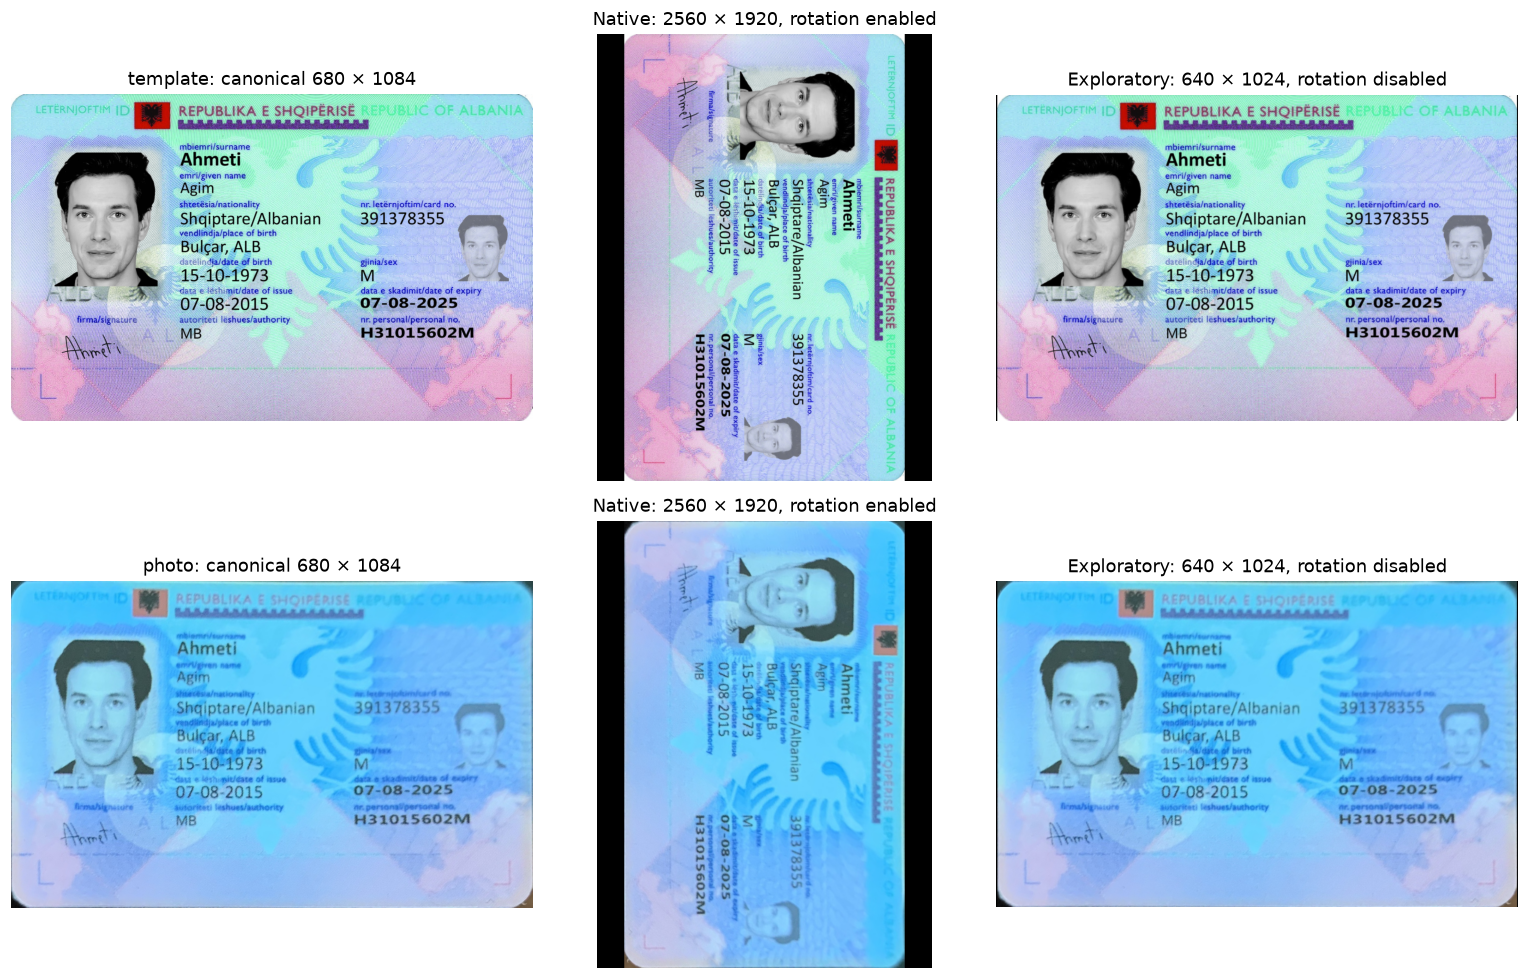

In [9]:
def display_pixels(tensor, selected_processor):
    array = tensor[0].permute(1, 2, 0).cpu().numpy()
    mean = np.asarray(selected_processor.image_processor.image_mean)
    std = np.asarray(selected_processor.image_processor.image_std)
    return np.clip(array * std + mean, 0, 1)

fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for row, source in enumerate(canonical):
    axes[row, 0].imshow(canonical[source])
    axes[row, 0].set_title(f'{source}: canonical 680 × 1084')
    axes[row, 1].imshow(display_pixels(processed[source, 'native'], native_processor))
    axes[row, 1].set_title('Native: 2560 × 1920, rotation enabled')
    axes[row, 2].imshow(display_pixels(processed[source, 'landscape'], processor))
    axes[row, 2].set_title('Exploratory: 640 × 1024, rotation disabled')
    for axis in axes[row]:
        axis.axis('off')
fig.tight_layout()
fig.savefig(RUN / 'processor_comparison.png', bbox_inches='tight')
plt.show()

### 4.2 Check small text at its actual processed resolution

A scaled-down plot of a whole document can conceal loss of text detail. Zoom
into the surname on the canonical and processed landscape card. The rectangle
is used **only for this diagnostic visualization**; it never restricts what Donut
sees. We map rectangle edges into processed coordinates while allowing for
centered padding.

The transformed view must still contain the intended field. Inspect letters,
diacritics, and surrounding labels; seeing a readable surname here does not prove
all seven fields remain readable or that the model will recognize them.

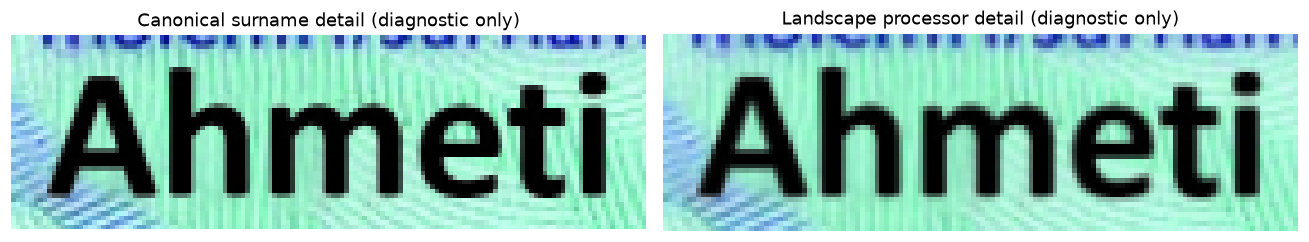

In [10]:
shape = region(template_record, 'surname')['shape_attributes']
native_h, native_w = bgr['template'].shape[:2]
x, y, w, h = [shape[k] for k in ['x', 'y', 'width', 'height']]
x0, y0 = round(x * width / native_w), round(y * height / native_h)
x1, y1 = round((x + w) * width / native_w), round((y + h) * height / native_h)
# Include a little context so registration and clipping are visible.
x0, y0, x1, y1 = max(0, x0 - 8), max(0, y0 - 8), min(width, x1 + 8), min(height, y1 + 8)
preview_processor = DonutImageProcessorPil.from_pretrained(
    checkpoint, local_files_only=True, **policy['exploratory_processor'], do_normalize=False,
)
processed_preview = preview_processor(images=canonical['template'], return_tensors='pt')['pixel_values'][0].permute(1, 2, 0).numpy()
# PIL backend: resize the short edge to 640, then thumbnail to the canvas.
scale = min(1024 / width, 640 / height)
content_w, content_h = int(width * scale), int(height * scale)
left, top = (1024 - content_w) // 2, (640 - content_h) // 2
px0, px1 = round(x0 * scale) + left, round(x1 * scale) + left
py0, py1 = round(y0 * scale) + top, round(y1 * scale) + top
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].imshow(canonical['template'][y0:y1, x0:x1], interpolation='nearest')
axes[0].set_title('Canonical surname detail (diagnostic only)')
axes[1].imshow(np.clip(processed_preview[py0:py1, px0:px1], 0, 1), interpolation='nearest')
axes[1].set_title('Landscape processor detail (diagnostic only)')
for axis in axes:
    axis.axis('off')
fig.tight_layout()
fig.savefig(RUN / 'surname_detail.png', bbox_inches='tight')
plt.show()

## 5. Inspect prompts and tokenization before generation

A task prompt is a decoder prefix, not a natural-language instruction the model
necessarily understands. This pretrained snapshot already has `<s_synthdog>` and
`<s_iitcdip>` tokens. We use its existing synthetic-document prefix for a smoke
generation. It does **not** ask for our seven fields.

Compare those prefixes with proposed custom task/field tags. Without vocabulary
registration, a tag may become several ordinary tokens rather than one schema
symbol. Even after registration, the model needs resized embeddings and
fine-tuning to learn its meaning.

**Predict first:** how many tokens will `<s_document_number>` produce in the
unchanged tokenizer? Inspect IDs and pieces rather than assuming the brackets
make it special.

In [11]:
token_rows = []
for text in ['<s_synthdog>', '<s_iitcdip>', '<s_alb_id>', '<s_document_number>', 'EXAMPLE', '1999-04-12']:
    ids = tokenizer(text, add_special_tokens=False)['input_ids']
    token_rows.append({'text': text, 'token_count': len(ids), 'ids': ids,
                       'pieces': tokenizer.convert_ids_to_tokens(ids)})
display(pd.DataFrame(token_rows))
prompt_ids = tokenizer(policy['prompt'], add_special_tokens=False, return_tensors='pt')['input_ids']
assert prompt_ids.shape == (1, 1)
assert tokenizer.convert_ids_to_tokens(prompt_ids[0].tolist()) == [policy['prompt']]
print('Smoke prompt:', policy['prompt'], '| IDs:', prompt_ids.tolist())

,text,token_count,ids,pieces
0,<s_synthdog>,1,[57524],[<s_synthdog>]
1,<s_iitcdip>,1,[57523],[<s_iitcdip>]
2,<s_alb_id>,8,"[41040, 46192, 41403, 35353, 34796, 41403, 439...","[▁<, s, _, al, b, _, id, >]"
3,<s_document_number>,8,"[41040, 46192, 41403, 4417, 41403, 34249, 7352...","[▁<, s, _, document, _, num, ber, >]"
4,EXAMPLE,3,"[35585, 52532, 12584]","[▁EX, AMP, LE]"
5,1999-04-12,4,"[52948, 52165, 51336, 57404]","[▁1999, -, 04, -12]"


Smoke prompt: <s_synthdog> | IDs: [[57524]]


### 5.1 A safe vocabulary experiment

Load a second tokenizer for an isolated demonstration. Register a custom task
token and opening/closing tokens for all seven fields. The original tokenizer
used for real inference remains unchanged. We deliberately do not resize or
train the model in notebook A.

**Common mistake:** adding tokens to a tokenizer and then sending their new IDs
to a model whose embedding table still has the old number of rows. A future
training notebook must resize embeddings, initialize/train the new rows, and
save the model and tokenizer together.

In [12]:
probe_tokenizer = AutoTokenizer.from_pretrained(checkpoint, local_files_only=True)
schema_tokens = ['<s_alb_id>'] + [tag for field in REQUIRED_FIELDS for tag in (f'<s_{field}>', f'</s_{field}>')]
added = probe_tokenizer.add_special_tokens({'additional_special_tokens': schema_tokens})
probe_ids = probe_tokenizer('<s_document_number>', add_special_tokens=False)['input_ids']
assert len(probe_ids) == 1 and added == 15
assert len(tokenizer) == saved_config['decoder']['vocab_size']
display(pd.DataFrame([{
    'original_vocabulary': len(tokenizer), 'isolated_probe_vocabulary': len(probe_tokenizer),
    'added_schema_tokens': added, 'new_field_token_id': probe_ids[0],
}]))
print('The unchanged pretrained model will never receive these new IDs in this notebook.')

,original_vocabulary,isolated_probe_vocabulary,added_schema_tokens,new_field_token_id
0,57525,57540,15,57526


The unchanged pretrained model will never receive these new IDs in this notebook.


## 6. Load weights and understand the architecture budget

Load the local checkpoint in float32, keep the pretrained parameters unchanged,
and select eager attention explicitly. `eval()` disables training behavior such
as dropout; `torch.inference_mode()` disables gradient bookkeeping during calls.
They solve different problems, so we use both.

Inspect missing/unexpected/mismatched loading keys. We fail on an unexplained
weight mismatch rather than quietly executing newly initialized layers. The
model is pre-trained only; no `alb_id` task is embedded in its name.

**Predict first:** estimate weight memory as parameter count × 4 bytes. Why will
the process and peak GPU memory be larger than this weight-only estimate?

In [13]:
synchronize()
load_start = time.perf_counter()
model, loading_info = VisionEncoderDecoderModel.from_pretrained(
    checkpoint, local_files_only=True, dtype=torch.float32,
    attn_implementation=policy['attention_implementation'], output_loading_info=True,
)
print('Loading diagnostics:', loading_info)
assert not any(loading_info.get(k) for k in ['missing_keys', 'unexpected_keys', 'mismatched_keys', 'error_msgs'])
loading_info = {key: sorted(value) if isinstance(value, set) else value for key, value in loading_info.items()}
model.eval()
model.to(device)
synchronize()
load_elapsed_ms = (time.perf_counter() - load_start) * 1000
memory_rows.append(memory_snapshot('loaded float32 model'))
parameter_rows = []
for name, module in [('encoder', model.encoder), ('decoder', model.decoder), ('whole model', model)]:
    count = sum(p.numel() for p in module.parameters())
    parameter_rows.append({'component': name, 'parameters': count,
                           'weight_only_mib': sum(p.numel() * p.element_size() for p in module.parameters()) / 2**20})
parameter_table = pd.DataFrame(parameter_rows)
assert all(p.dtype == torch.float32 for p in model.parameters())
assert model.decoder.get_input_embeddings().num_embeddings == len(tokenizer)
display(parameter_table)
print(f'One-time local load and device transfer: {load_elapsed_ms:.1f} ms (excluded from request time)')
display(pd.DataFrame(memory_rows))

Loading weights:   0%|          | 0/484 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 484/484 [00:00<00:00, 50857.88it/s]

Loading diagnostics: {'missing_keys': set(), 'unexpected_keys': set(), 'mismatched_keys': set(), 'error_msgs': []}


,component,parameters,weight_only_mib
0,encoder,74180728,282.977020
1,decoder,127671296,487.027344
2,whole model,201852024,770.004364


One-time local load and device transfer: 254.1 ms (excluded from request time)


,stage,process_rss_mib,cuda_allocated_mib,cuda_reserved_mib,cuda_peak_allocated_mib,cuda_peak_reserved_mib,device_free_mib,device_total_mib
0,session before loading,1020.371094,0.00000,0.0,0.00000,0.0,3654.3125,3726.375
1,loaded float32 model,1654.078125,771.54541,786.0,771.54541,786.0,2868.3125,3726.375


### 6.1 Swin produces spatial features, not recognized field strings

The 4 × 4 patch embedding starts with a grid of small image regions. This
checkpoint has four stages, with patch merging between stages: spatial grids
shrink while channel width grows. Attention operates in windows, and shifted
windows let information cross neighboring boundaries. These are learned visual
features, not OCR characters or field bounding boxes.

For our dimensions, the total spatial stride is 32. Predict the final number
of visual positions as `(640 / 32) × (1024 / 32)` before running the encoder.
The table below derives stage dimensions from the loaded configuration; the next
cell checks the actual returned final tensor.

In [14]:
encoder_config = model.encoder.config
tensor_h, tensor_w = processed['template', 'landscape'].shape[-2:]
stage_rows = []
for stage, depth in enumerate(encoder_config.depths):
    stride = encoder_config.patch_size * (2 ** stage)
    stage_rows.append({'stage': stage + 1, 'blocks': depth, 'stride': stride,
                       'grid_height': tensor_h // stride, 'grid_width': tensor_w // stride,
                       'channels': encoder_config.embed_dim * (2 ** stage)})
display(pd.DataFrame(stage_rows))
print('Window size:', encoder_config.window_size)
print('Decoder layers:', model.decoder.config.decoder_layers)
print('Decoder hidden width:', model.decoder.config.d_model)
print('Maximum decoder positions:', model.decoder.config.max_position_embeddings)

,stage,blocks,stride,grid_height,grid_width,channels
0,1,2,4,160,256,128
1,2,2,8,80,128,256
2,3,14,16,40,64,512
3,4,2,32,20,32,1024


Window size: 10
Decoder layers: 4
Decoder hidden width: 1024
Maximum decoder positions: 1536


In [15]:
pixels_device = processed['template', 'landscape'].to(device)
synchronize()
encoder_start = time.perf_counter()
with torch.inference_mode():
    encoder_output = model.encoder(pixel_values=pixels_device, return_dict=True)
synchronize()
encoder_elapsed_ms = (time.perf_counter() - encoder_start) * 1000
encoder_shape = list(encoder_output.last_hidden_state.shape)
expected_positions = (tensor_h // stage_rows[-1]['stride']) * (tensor_w // stage_rows[-1]['stride'])
assert encoder_shape == [1, expected_positions, encoder_config.hidden_size]
assert torch.isfinite(encoder_output.last_hidden_state).all()
print('Actual encoder output [batch, visual positions, channels]:', encoder_shape)
print(f'One exploratory encoder call: {encoder_elapsed_ms:.1f} ms; not a warmed benchmark.')
memory_rows.append(memory_snapshot('after standalone encoder inspection'))

Actual encoder output [batch, visual positions, channels]: [1, 640, 1024]
One exploratory encoder call: 479.0 ms; not a warmed benchmark.


## 7. Inspect one next-token decision

The decoder takes the prompt and attends to encoded image features. Its output
contains a score (logit) for every vocabulary entry at every input position.
Softmax converts the final-position scores into a next-token distribution.
Greedy decoding chooses the largest score and repeats this process using its
own chosen token as context.

The table shows the first decision **conditioned on this image and prompt**.
These probabilities are not calibrated field confidence, and they do not tell
us whether a generated identity value is correct. We only inspect this small
distribution, not every attention matrix.

In [16]:
prompt_device = prompt_ids.to(device)
with torch.inference_mode():
    first_step = model.decoder(
        input_ids=prompt_device, encoder_hidden_states=encoder_output.last_hidden_state,
        use_cache=False, return_dict=True,
    )
assert list(first_step.logits.shape) == [1, 1, len(tokenizer)]
probabilities = first_step.logits[0, -1].float().softmax(dim=-1)
values, ids = probabilities.topk(8)
next_token_table = pd.DataFrame([
    {'rank': rank + 1, 'id': token_id, 'piece': tokenizer.convert_ids_to_tokens(token_id),
     'decoded_piece': tokenizer.decode([token_id], clean_up_tokenization_spaces=False),
     'next_token_probability': probability}
    for rank, (token_id, probability) in enumerate(zip(ids.cpu().tolist(), values.cpu().tolist()))
])
display(next_token_table)
del first_step, probabilities, values, ids

,rank,id,piece,decoded_piece,next_token_probability
0,1,42990,▁,,0.265429
1,2,46982,▁R,R,0.235961
2,3,918,▁mbi,mbi,0.095619
3,4,37565,▁m,m,0.057861
4,5,47793,▁n,n,0.035901
5,6,28432,▁E,E,0.027541
6,7,15982,▁r,r,0.027077
7,8,7256,▁MB,MB,0.021358


### 7.1 Generate a short sequence from the inspected encoder output

This call reuses the encoder features we just examined. It demonstrates the
decoder path; it is **not** an end-to-end request timing. Use the native task
prefix as the decoder start token so the generation helper does not prepend an
unintended extra prefix.

We allow at most 48 new tokens, use greedy decoding with one beam, and enable the
decoder KV cache. The cache retains intermediate attention state within this
generation; it does not reuse a previous document answer. Explicitly disable
forced EOS so a token limit cannot masquerade as the model voluntarily stopping.
These are investigation settings, not the future adopted Donut policy.

**Version-specific detail:** in Transformers 5.19, `None` fields inside a supplied
`GenerationConfig` are filled from checkpoint defaults. This checkpoint defaults
to forcing EOS at the limit. Passing generation arguments directly to `generate`
applies our explicit `forced_eos_token_id=None` *after* that default filling. We
also pass `max_length=None` so the 48-new-token bound is the only length setting.
Inspect the saved checkpoint default and explicit arguments below.

In [17]:
generation_kwargs = {
    **policy['generation'],
    'decoder_start_token_id': int(prompt_ids[0, 0]),
    'bos_token_id': tokenizer.bos_token_id, 'eos_token_id': tokenizer.eos_token_id,
    'pad_token_id': tokenizer.pad_token_id,
}
assert generation_kwargs['forced_eos_token_id'] is None and generation_kwargs['max_length'] is None
print('Checkpoint forced EOS default:', model.generation_config.forced_eos_token_id)
print('Explicit generation arguments:', generation_kwargs)
with torch.inference_mode():
    traced_ids = model.generate(
        encoder_outputs=encoder_output, decoder_input_ids=prompt_device,
        **generation_kwargs,
    )[0].cpu().tolist()
raw_sequence = tokenizer.decode(traced_ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)
readable_sequence = tokenizer.decode(traced_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)
print('Raw sequence with special tokens:', repr(raw_sequence))
print('Readable sequence:', repr(readable_sequence))
print('EOS emitted among new tokens:', tokenizer.eos_token_id in traced_ids[prompt_ids.shape[1]:])
display(pd.DataFrame({'position': range(min(24, len(traced_ids))), 'id': traced_ids[:24],
                      'piece': tokenizer.convert_ids_to_tokens(traced_ids[:24])}))

Checkpoint forced EOS default: 2
Explicit generation arguments: {'do_sample': False, 'num_beams': 1, 'max_new_tokens': 48, 'max_length': None, 'use_cache': True, 'forced_eos_token_id': None, 'decoder_start_token_id': 57524, 'bos_token_id': 0, 'eos_token_id': 2, 'pad_token_id': 1}


Raw sequence with special tokens: '<s_synthdog> mblemrijsurname Ahmed emrigiven name Agim shteeeesia/nationality Shqiptare/Albanian vendindia/place of birth Bulcar, ALB date in dialdate of'
Readable sequence: 'mblemrijsurname Ahmed emrigiven name Agim shteeeesia/nationality Shqiptare/Albanian vendindia/place of birth Bulcar, ALB date in dialdate of'
EOS emitted among new tokens: False


,position,id,piece
0,0,57524,<s_synthdog>
1,1,42990,▁
2,2,39570,mble
3,3,38844,m
4,4,21620,rij
5,5,49532,sur
6,6,4131,name
7,7,38318,▁Ahmed
8,8,37762,▁em
9,9,1002,rig


### 7.2 A parser does not make an arbitrary sequence a seven-field answer

The processor's convenience `token2json` helper can interpret Donut-style tags.
Inspect what it returns for our raw pretrained output and whether the keys equal
the required schema. A text container or parseable dictionary is not necessarily
a valid extraction result. We preserve the full sequence regardless.

Notebook B will define and test a strict project parser: missing/extra/duplicate
keys, unbalanced tags, empty values, and truncation must have explicit behavior.
We do not adopt the convenience parser or invent correction rules here.

In [18]:
parser_probe = processor.token2json(raw_sequence)
schema_keys_match = isinstance(parser_probe, dict) and set(parser_probe) == set(REQUIRED_FIELDS)
print('Convenience parser probe:', parser_probe)
print('Exactly the seven required keys:', schema_keys_match)
print('No accuracy is computed: this base model has not learned our extraction task.')
# Remove retained inspection tensors before measuring independent complete calls.
del encoder_output, pixels_device, prompt_device
gc.collect()
if device.type == 'cuda':
    torch.cuda.empty_cache()

Convenience parser probe: {'text_sequence': ' mblemrijsurname Ahmed emrigiven name Agim shteeeesia/nationality Shqiptare/Albanian vendindia/place of birth Bulcar, ALB date in dialdate of'}
Exactly the seven required keys: False
No accuracy is computed: this base model has not learned our extraction task.


## 8. Run complete smoke requests on the paired views

Now start from each in-memory canonical array. Time preprocessing, device
transfer, full `generate` (including the encoder), and string decoding. Record
the full request too. Synchronize CUDA at each boundary, reset peak counters per
request, and retain raw tokens, text, termination, and memory.

This is **two smoke observations from one identity**, with no warm-up/repetition
protocol. The first call may include one-time setup. These timings describe what
ran; they are not stable latency estimates, not a comparison with OCR, and not
service/load evidence. Dataset/model loading, plotting, file writing, and the
convenience parser probe are outside this request boundary.

**Predict first:** should the two views generate identical text? A shared identity
does not imply identical pixels or identical model behavior.

In [19]:
smoke_results = []
for source, image in canonical.items():
    gc.collect()
    if device.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(device)
    baseline = memory_snapshot(f'{source}: baseline')
    synchronize()
    request_start = time.perf_counter()
    batch = processor(images=image, return_tensors='pt')['pixel_values']
    preprocess_end = time.perf_counter()
    batch_device = batch.to(device)
    decoder_input = prompt_ids.to(device)
    synchronize()
    transfer_end = time.perf_counter()
    with torch.inference_mode():
        output_ids = model.generate(
            pixel_values=batch_device, decoder_input_ids=decoder_input,
            **generation_kwargs,
        )[0].cpu().tolist()
    synchronize()
    generation_end = time.perf_counter()
    raw = tokenizer.decode(output_ids, skip_special_tokens=False, clean_up_tokenization_spaces=False)
    readable = tokenizer.decode(output_ids, skip_special_tokens=True, clean_up_tokenization_spaces=False)
    request_end = time.perf_counter()
    new_ids = output_ids[prompt_ids.shape[1]:]
    reached_eos = tokenizer.eos_token_id in new_ids
    result = {
        'identity_key': identity_key, 'split': 'train', 'source': source,
        'input_shape': list(image.shape), 'processed_shape': list(batch.shape),
        'raw_sequence': raw, 'readable_sequence': readable, 'token_ids': output_ids,
        'new_token_count': len(new_ids), 'eos_emitted': reached_eos,
        'length_limit_reached_without_eos': not reached_eos and len(new_ids) == policy['generation']['max_new_tokens'],
        'preprocessing_ms': (preprocess_end - request_start) * 1000,
        'transfer_ms': (transfer_end - preprocess_end) * 1000,
        'model_generation_ms': (generation_end - transfer_end) * 1000,
        'string_decode_ms': (request_end - generation_end) * 1000,
        'smoke_request_ms': (request_end - request_start) * 1000,
        'baseline_memory': baseline, 'end_memory': memory_snapshot(f'{source}: after generation'),
    }
    smoke_results.append(result)
    print(source, 'raw:', repr(raw))
    print(source, 'EOS:', reached_eos, '| new tokens:', len(new_ids))
    del batch_device, decoder_input, batch
assert smoke_results[0]['token_ids'] == traced_ids, 'Standalone trace and full template generation disagree.'
display(pd.DataFrame([{k: r[k] for k in ['source', 'new_token_count', 'eos_emitted',
                                       'preprocessing_ms', 'transfer_ms', 'model_generation_ms', 'smoke_request_ms']}
                      for r in smoke_results]))
display(pd.DataFrame([r['end_memory'] for r in smoke_results]))

template raw: '<s_synthdog> mblemrijsurname Ahmed emrigiven name Agim shteeeesia/nationality Shqiptare/Albanian vendindia/place of birth Bulcar, ALB date in dialdate of'
template EOS: False | new tokens: 48


photo raw: '<s_synthdog> Abmi ns. ns. ns. ns. ns. ns. ns. ns. ns. ns. ns. ns. ns. ns. ns. '
photo EOS: False | new tokens: 48


,source,new_token_count,eos_emitted,preprocessing_ms,transfer_ms,model_generation_ms,smoke_request_ms
0,template,48,False,11.807761,0.805671,497.269795,509.936307
1,photo,48,False,11.077443,0.797288,498.931214,510.849922


,stage,process_rss_mib,cuda_allocated_mib,cuda_reserved_mib,cuda_peak_allocated_mib,cuda_peak_reserved_mib,device_free_mib,device_total_mib
0,template: after generation,2087.3125,787.670898,1310.0,1144.791992,1310.0,2324.3125,3726.375
1,photo: after generation,2087.3125,787.670898,1310.0,1144.791992,1310.0,2324.3125,3726.375


## 9. Save evidence and turn observations into a bounded decision

Save policy, software/hardware, exact input/artifact hashes, processor settings,
tensor shapes, loading diagnostics, token traces, raw generations, and memory.
This allows the experiment to be audited without repeating the download or
relying on terminal history. The execution runner separately retains the input
and executed notebooks plus code hashes, including failed runs.

The model must still be unchanged: our isolated vocabulary demonstration cannot
leak new tokens into the actual decoder. No training optimizer was created.

In [20]:
assert len(tokenizer) == model.decoder.get_input_embeddings().num_embeddings
assert not model.training and all(p.grad is None for p in model.parameters())
assert all(result['split'] == 'train' for result in smoke_results)
provenance = {
    'policy_sha256': sha256(policy_path), 'split_sha256': sha256(split_path),
    'geometry_policy_sha256': sha256(geometry_path),
    'images_sha256': {s: sha256(p) for s, p in image_paths.items()},
    'annotation_files_sha256': {'template': sha256(template_annotations), 'photo': sha256(photo_annotations)},
    'canonical_pixels_sha256': {s: hashlib.sha256(image.tobytes()).hexdigest() for s, image in canonical.items()},
    'processor_class': type(image_processor).__name__, 'tokenizer_class': type(tokenizer).__name__,
    'processor_source_sha256': sha256(inspect.getfile(DonutImageProcessorPil)),
    'model_source_sha256': sha256(inspect.getfile(VisionEncoderDecoderModel)),
}
summary = {
    'experiment_version': policy['experiment_version'], 'policy': policy,
    'identity_key': identity_key, 'sources_loaded': list(canonical),
    'identities_loaded': 1, 'validation_images_loaded': 0, 'test_images_loaded': 0,
    'optimizer_steps': 0, 'environment': environment, 'provenance': provenance,
    'artifacts': artifacts, 'loading_info': loading_info,
    'native_processor': native_image_processor.to_dict(),
    'exploratory_processor': image_processor.to_dict(),
    'generation_arguments': generation_kwargs,
    'checkpoint_generation_defaults': model.generation_config.to_dict(),
    'parameter_counts': parameter_table.to_dict(orient='records'),
    'encoder_shape': encoder_shape, 'stage_dimensions': stage_rows,
    'load_and_transfer_ms': load_elapsed_ms, 'single_encoder_call_ms': encoder_elapsed_ms,
    'memory_stages': memory_rows, 'parser_probe': parser_probe,
    'parser_probe_has_required_keys': schema_keys_match,
    'traced_template_ids': traced_ids, 'smoke_results': smoke_results,
    'training_feasibility_demonstrated': False,
}
write_json(RUN / 'summary.json', summary)
preprocess_table.to_csv(RUN / 'preprocessing.csv', index=False)
next_token_table.to_csv(RUN / 'first_token_distribution.csv', index=False)
write_json(RUN / 'tokenization.json', token_rows)
write_json(RUN / 'policy.json', policy)
files = sorted(path for path in RUN.iterdir() if path.is_file())
write_json(RUN / 'artifact_hashes.json', {p.name: sha256(p) for p in files})
print('Saved evidence:', RUN.relative_to(ROOT))
print('Artifacts:', [p.name for p in files])

Saved evidence: outputs/phase4_foundations/20261013T130934816247Z
Artifacts: ['canonical_pair.png', 'canonical_photo.png', 'canonical_template.png', 'checkpoint_manifest.json', 'environment.json', 'first_token_distribution.csv', 'input.ipynb', 'policy.json', 'preprocessing.csv', 'processor_comparison.png', 'summary.json', 'surname_detail.png', 'tokenization.json']


In [21]:
total_parameters = int(parameter_table.loc[parameter_table['component'].eq('whole model'), 'parameters'].iloc[0])
peak = max(r['end_memory'].get('cuda_peak_allocated_mib', 0) for r in smoke_results)
terminated = sum(r['eos_emitted'] for r in smoke_results)
display(Markdown(f'''
### Observed in this execution

- **Identity boundary:** `{identity_key}`, two views, one training identity; no validation/test images loaded.
- **Model:** {total_parameters:,} parameters loaded from revision `{policy['revision']}`.
- **Processed landscape tensor:** `{list(processed['template', 'landscape'].shape)}`.
- **Actual encoder output:** `{encoder_shape}`.
- **Generation:** {terminated}/2 smoke sequences emitted EOS; inspect the raw text and termination flags above.
- **Peak CUDA allocated during the two smoke calls:** {peak:.1f} MiB (0 means this was a CPU run).
- **Sanity check:** standalone template encoder/decoder trace matched the complete template generation exactly.
- **Next decision:** carry the bounded landscape configuration forward as a candidate to investigate,
  then measure a full training step in notebook B. This is not an adopted resolution or evidence training fits.
'''))


### Observed in this execution

- **Identity boundary:** `alb_id/02`, two views, one training identity; no validation/test images loaded.
- **Model:** 201,852,024 parameters loaded from revision `a959cf33c20e09215873e338299c900f57047c61`.
- **Processed landscape tensor:** `[1, 3, 640, 1024]`.
- **Actual encoder output:** `[1, 640, 1024]`.
- **Generation:** 0/2 smoke sequences emitted EOS; inspect the raw text and termination flags above.
- **Peak CUDA allocated during the two smoke calls:** 1144.8 MiB (0 means this was a CPU run).
- **Sanity check:** standalone template encoder/decoder trace matched the complete template generation exactly.
- **Next decision:** carry the bounded landscape configuration forward as a candidate to investigate,
  then measure a full training step in notebook B. This is not an adopted resolution or evidence training fits.


## 10. Reflection and guided exercises

Before moving to notebook B, explain these in your own words:

1. Which operations transformed geometry, which transformed pixel values, and
   which transformed output text? Why should these not share one vague name?
2. Why did the native processor rotate the card? How did you establish the
   actual height/width rather than interpreting the historical list by guesswork?
3. What does `[1, 640, 1024]` mean at the encoder boundary? Why are its 640
   positions neither characters nor the seven output fields?
4. Why was `<s_synthdog>` a suitable *smoke prefix* but insufficient for our task?
   What would registering `<s_document_number>` actually change?
5. If the generated text contains the correct surname, why is this not a
   seven-field extraction result or an accuracy estimate?
6. If a sequence reaches its token limit without EOS, what should later reports
   retain? Why would forcing EOS at the limit hide useful evidence?
7. Why do the memory/timing observations not establish training feasibility or
   a speed advantage over OCR?

**Exercise A — pixels, no model rerun:** in a scratch copy, try another landscape
processor size divisible by 32. Show its actual tensor and a surname detail. State
what changed and what remains unknown; do not select a training policy by appearance alone.

**Exercise B — vocabulary only:** tokenize a name with diacritics and a date with
the unchanged tokenizer. Decode the IDs and identify whitespace/special tokens.
Do not infer that one token means one character.

**Exercise C — generation in a new evidence run:** change only the maximum new
tokens in a separately versioned experiment configuration. Preserve the original
run, compare termination and raw sequences, and explain why longer output does
not automatically mean better extraction. Test remains sealed.

## Troubleshooting

| Symptom | Check and response |
|---|---|
| Missing checkpoint or hash mismatch | Run the pinned preparation command; retain the declared revision and all files together. |
| CUDA unavailable | Check `nvidia-smi`, `.venv`, and GPU permissions; explicitly select CPU if intended. |
| CUDA out of memory | Restart the kernel to release stale models, inspect other GPU use, then document any smaller exploratory configuration as a new run. |
| Card looks rotated or stretched | Inspect named processor dimensions, alignment flag, and the reconstructed pixels before touching the neural model. |
| New token ID exceeds embedding rows | Keep the isolated tokenizer experiment separate; embedding resize and task training belong to notebook B/C. |
| Output looks unstructured or repeats | Preserve it: this is a pretrained smoke check, not an adapted seven-field extractor. |
| Fresh clone cannot find MIDV/weights | Restore the local artifacts using the documented setup; datasets and checkpoints are intentionally ignored by Git. |

## Next workshop and primary references

Notebook B will build complete seven-field targets, test strict parsing and
round trips, audit paired training/validation observations, and measure a real
forward/backward/optimizer step. The current notebook has not answered those questions.

- [Pinned pretrained model card](https://huggingface.co/naver-clova-ix/donut-base/tree/a959cf33c20e09215873e338299c900f57047c61)
- [Donut paper](https://arxiv.org/abs/2111.15664) and [official implementation](https://github.com/clovaai/donut)
- [Swin paper](https://arxiv.org/abs/2103.14030)
- [Transformers Donut API](https://huggingface.co/docs/transformers/model_doc/donut)
- [Vision encoder-decoder API](https://huggingface.co/docs/transformers/model_doc/vision-encoder-decoder)
- [PyTorch CUDA memory accounting](https://docs.pytorch.org/docs/stable/notes/cuda.html#memory-management)
- [PyTorch inference mode](https://docs.pytorch.org/docs/stable/generated/torch.autograd.grad_mode.inference_mode.html)